# A delay inside a nonlinear term: $x\,x(t-d)$

**Showcases:** a bare hard delay inside a product. The vertex $x\,x(t-d)$ has one delayed leg; the loops use the $(n, n)$ Padé approximant of $e^{-i\omega d}$, whose constant part (the value at $\omega \to \infty$) acts as a direct, undelayed term at that leg (the run reports `approximant: 'pade'`); the tree is exact.

$$\dot x = -a x + b - c\,x\,x(t-d) + \xi, \qquad \langle\xi\xi\rangle = 2D\delta .$$

The mean field solves $a x^* + c x^{*2} = b$ (here $x^* = 0.732$). This is a delayed logistic-type feedback: growth is limited by the population a time $d$ earlier.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
from api.sde import SDE
from api.noise import Gaussian
from api.delay import Kernel
from api import compute_cumulants

def delay_report(r):
    d = r.get('delay') or {}
    return {k: d.get(k) for k in ('tree', 'approximant', 'n', 'orders_run', 'target_met') if k in d}

In [3]:
P = dict(a=1.0, b=1.0, c=0.5, d=0.5, D=0.1)
m = (SDE('delayed product')
     .parameter('a', default=P['a']).parameter('b', default=P['b']).parameter('c', default=P['c'])
     .parameter('d', default=P['d'], domain='positive').parameter('D', default=P['D'], domain='positive')
     .field('x')
     .drift('x', '-a*x + b - c*x*x(t - d)')
     .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
m.show()
tau = np.linspace(-6, 6, 49)
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    r2 = compute_cumulants(m.build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                           tau_grid=tau, parallel=False, verbose=False, delay={'tol': 1e-4})
    r1 = compute_cumulants(m.build(), k=1, max_ell=1, external_fields=[('x', 1)], tau_grid=np.array([0.0]),
                           parallel=False, verbose=False, delay={'tol': 1e-4})
xs = float(np.atleast_1d(r1['mf_values']['xstar'])[0])
mean_1l = xs + complex(r1['C_tau_by_ell'][1][0]).real
print(f"{time.time() - t0:.0f} s; delay:", delay_report(r2))
print(f"mean: saddle {xs:.5f}, with one loop {mean_1l:.5f}")
C = ells(r2)

# SDE 'delayed product' (ito)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-a*x[i] + b - c*x[i]*Conv(delay_d, x[i])))
    - (D*xt[i]^2)
    for i in pop)
''')
.equation(lhs='Dt*x[i] + x[i]', rhs='(-a*x[i] + b - c*x[i]*((1))*(x[i])) + x[i]', population='pop')
# note: mean-field equation of 'x': rhs has no field-independent linear term in x; added x[i] to both sides (lhs 'Dt*x[i] + x[i]', c = 1; the residual and the linear stability are unchanged).
34 s; delay: {'tree': 'exact', 'approximant': 'pade', 'n': 8, 'orders_run': [4, 8], 'target_met': True}
mean: saddle 0.73205, with one loop 0.72424


In [4]:
from numba import njit

def autocov(series_list, max_lag):
    # connected autocovariance from several independent runs (mean removed per run); mean and SE over runs
    out = []
    for s in series_list:
        s = s - s.mean()
        n = len(s); f = np.fft.rfft(s, 2 * n)
        ac = np.fft.irfft(f * np.conj(f))[:max_lag + 1] / (n - np.arange(max_lag + 1))
        out.append(ac)
    out = np.array(out)
    return out.mean(0), out.std(0, ddof=1) / np.sqrt(len(out))

@njit(cache=False)
def sim(n_steps, dt, a, b, c, d, D, x0, every, seed):
    np.random.seed(seed)
    lag = int(d / dt + 0.5); buf = np.full(lag, x0); p = 0
    x = x0; sq = np.sqrt(2.0 * D * dt)
    out = np.empty(n_steps // every)
    for k in range(n_steps + 20000):
        xd = buf[p]
        x_new = x + dt * (-a * x + b - c * x * xd) + sq * np.random.randn()
        buf[p] = x; p = (p + 1) % lag
        x = x_new
        j = k - 20000
        if j >= 0 and j % every == 0 and j // every < out.shape[0]:
            out[j // every] = x
    return out

dt, every, T = 0.005, 10, 2.0e5
t0 = time.time()
runs = [sim(int(T / dt), dt, P['a'], P['b'], P['c'], P['d'], P['D'], xs, every, s) for s in range(8)]
lags = np.arange(0, 121, 4)
ac, se = autocov(runs, lags[-1]); ac, se = ac[lags], se[lags]
means = np.array([r.mean() for r in runs])
print(f"simulation {time.time() - t0:.0f} s; mean {means.mean():.5f} +- {means.std(ddof=1) / np.sqrt(len(means)):.5f}")

simulation 11 s; mean 0.72408 +- 0.00026


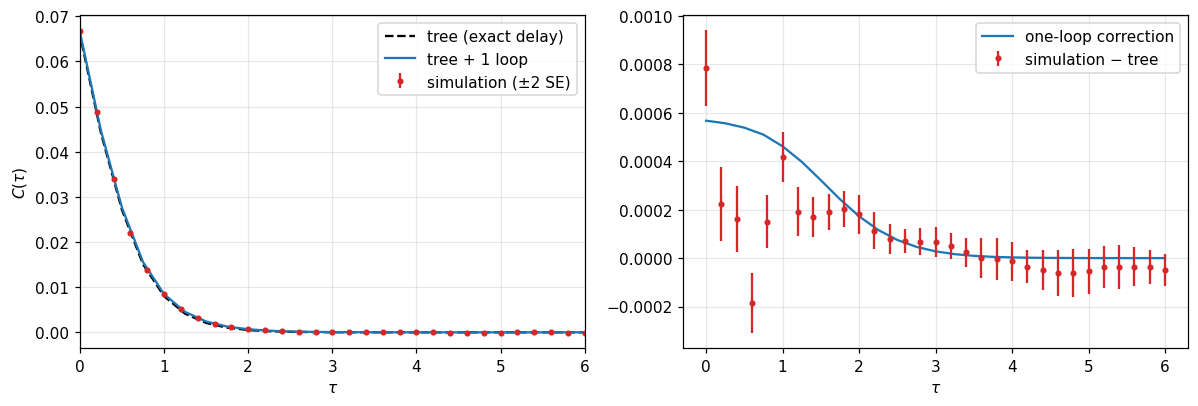

C(0): tree 0.06595, tree + 1 loop 0.06652, simulation 0.06674 +- 0.00008


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tau, C[0], 'k--', label='tree (exact delay)')
ax[0].plot(tau, C[0] + C[1], 'C0', label='tree + 1 loop')
ax[0].errorbar(lags * dt * every, ac, yerr=2 * se, fmt='o', ms=3, color='C3', label='simulation (±2 SE)')
ax[0].set_xlim(0, 6); ax[0].set_xlabel(r'$\tau$'); ax[0].set_ylabel(r'$C(\tau)$'); ax[0].legend()
pos = tau >= 0
ax[1].plot(tau[pos], C[1][pos], 'C0', label='one-loop correction')
ax[1].errorbar(lags * dt * every, ac - np.interp(lags * dt * every, tau, C[0]), yerr=2 * se, fmt='o', ms=3,
               color='C3', label='simulation − tree')
ax[1].set_xlabel(r'$\tau$'); ax[1].legend()
plt.tight_layout(); plt.show()
i0 = len(tau) // 2
print(f"C(0): tree {C[0][i0]:.5f}, tree + 1 loop {C[0][i0] + C[1][i0]:.5f}, simulation {ac[0]:.5f} +- {se[0]:.5f}")

The one-loop corrections shift the mean below the saddle (0.72424 against the simulated 0.72408 ± 0.00026) and raise the variance; the loop accounts for about three quarters of the simulated shift of $C(0)$ (0.06652 against 0.06674 ± 0.00008), the rest being the size of the next order plus the $O(\mathrm dt)$ Euler bias of the simulation.